# Training: physics-informed neural network (PINN) for a pigeon flock

This notebook trains the PINN of Kim et al. (2025), *Commanding Emergent Behavior with Neural Networks*
([original code](https://github.com/dongjokim03/Collective_motions_training)), on GPS tracks of a ten-pigeon flock
(Nagy et al. 2010, *Nature* 464, 890–893), and three modified versions of it.

**Idea.** A small neural network maps time $t$ to the positions $\mathbf r_i(t)$ of all 10 birds. Its time
derivatives (computed exactly by automatic differentiation) give velocities and accelerations. A physics law
with 25 trainable coefficients must explain the accelerations of the 9 followers (bird A is the leader):

$$\ddot{\mathbf r}_i=\frac{v_0-|\mathbf v_i|}{|\tau|}\,\hat{\mathbf v}_i+\sum_{j\neq i}\Big[f(d_{ij})\,w_d(\theta_{ij})\,\hat{\mathbf r}_{ij}+g(d_{ij})\,w_v(\theta_{ij})\,\hat{\mathbf v}_{ij}\Big]$$

- $d_{ij}$ is the distance between birds $i$ and $j$; $\hat{\mathbf r}_{ij}$, $\hat{\mathbf v}_{ij}$ are unit vectors of their relative position and velocity.
- $f(d)=\lambda_1 d^{p_1}+\lambda_2 d^{p_2}+\lambda_3 d^{p_3}+\lambda_4$ is the distance force ($f>0$ repels, $f<0$ attracts); $g(d)$ has the same form and aligns velocities when negative.
- $w(\theta)=\sigma\big(\sum_{m=1}^4 a_m\cos m\theta+a_5\big)$ weights a neighbour by its bearing $\theta$ (field of view).
- $v_0$ is the cruising speed and $\tau$ how quickly a bird returns to it.

**Loss** = position error in x + position error in y + physics residual (mean squared difference between the
network's accelerations and the law). Training: Adam (200 steps), then L-BFGS, both with early stopping.

**Variants** (the four methods compared):

| key | method | change |
|---|---|---|
| `full` | Baseline | the original method |
| `hic` | Hard initial condition | $\mathbf r(t)=\mathbf r_0+\mathbf v_0t+(t/T)^2R\,\mathrm{NN}(t)$, so position and velocity at $t=0$ equal the data |
| `aw2` | Self-adaptive loss weights | weights $w=100\,\sigma(\lambda)$, raised by gradient ascent during Adam |
| `pull_tail_v0` | Constrained law | distance cap 59 m, acceleration cap 10 m/s², minimum-pull penalty at 30–60 m, each bird's own $v_0$ |

**Reproducibility.** Results are bit-identical to the shipped ones (`results/`) on CPU with one thread and
the package versions in `requirements.txt`. One run takes about 5–40 minutes, so by default the notebook trains
one demonstration run (baseline, seed 3) and compares it with the shipped result. Set `VARIANTS_TO_TRAIN` and
`SEEDS` below to retrain more (the shipped results use seeds 0–9 for all four variants, about 5–10 hours).

In [1]:
# Standard library
import math
import random
import time
from pathlib import Path

# Third-party
# torch is imported BEFORE pandas on purpose: on Windows, pandas loads the optional package pyarrow,
# whose own older copy of a system library (msvcp140.dll) can otherwise stop torch from loading.
import torch
import torch.nn as nn
import torch.autograd as autograd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Settings

In [2]:
# ---- what to train (edit these two lines) ----
VARIANTS_TO_TRAIN = ['full']      # any keys of VARIANTS below, e.g. ['full', 'hic', 'aw2', 'pull_tail_v0']
SEEDS = [3]                       # random seeds; the shipped results use range(10) = 0, 1, ..., 9

# ---- files ----
DATA_CSV = Path("data/pigeon_flock_18980_to_19120.csv")   # 140 s of flight, one row every 0.2 s
RESULTS_DIR = Path("results")      # shipped results of our 40 runs (4 variants x seeds 0-9)
OUTPUT_DIR = Path("outputs")       # results of the runs trained in this notebook
FIGURES_DIR = Path("figures")
TRAIN_END = 19000.0                # s: training uses the first 20 s (18980-19000 s, 101 frames)

# ---- hyperparameters of the original notebook ----
EPOCH_ADAM = 200                   # Adam steps
EPOCH_LBFGS = 1000                 # maximum L-BFGS steps (each uses up to 20 loss evaluations)
ADAM_LEARNING_RATE = 0.001
LBFGS_LEARNING_RATE = 0.1
LBFGS_MAX_ITER = 20
PATIENCE = -21                     # early stopping compares the loss with the mean of the last 20 losses ...
TOLERANCE = 1e-4                   # ... and stops when the difference is smaller than this
PRINT_EVERY = 25                   # print progress every this many steps

# ---- settings of the modified methods ----
ADAPTIVE_RATE = 0.01                                     # gradient-ascent step size of the adaptive weights
PULL_DISTANCES = [30.0, 35.0, 40.0, 45.0, 50.0, 55.0, 60.0]   # m: where the pull penalty is checked
BASE_OPTIONS = {'hard_ic': False, 'adaptive_weights': False, 'distance_cap': None,
                'max_acceleration': None, 'pull_min': None, 'pull_weight': 10.0, 'per_bird_v0': False}
# {**BASE_OPTIONS, ...} copies the base settings and then overrides some of them
VARIANTS = {
    'full': {**BASE_OPTIONS, 'label': 'Baseline'},
    'hic': {**BASE_OPTIONS, 'label': 'Hard IC', 'hard_ic': True},
    'aw2': {**BASE_OPTIONS, 'label': 'Adaptive weights', 'adaptive_weights': True},
    'pull_tail_v0': {**BASE_OPTIONS, 'label': 'Constrained law', 'distance_cap': 59.0, 'max_acceleration': 10.0,
                     'pull_min': 1.5, 'per_bird_v0': True},
}

# One CPU thread: the model is tiny, so more threads do not help, and the results are bit-reproducible
torch.set_num_threads(1)

## Data

The CSV holds 140 s of flight (18980–19120 s, 701 frames). Training uses only the first 20 s; the rest is kept
for testing the learned law in `simulation.ipynb`. Positions are centred on one common mean, so the distances
between birds are unchanged.

In [3]:
AGENT_LABELS = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N']   # labels that may appear


def load_flock_data(table):
    """Turn trajectory rows into PyTorch tensors (same steps as the original notebook).

    Input:  table = DataFrame with columns t(s), X(m)_A, Y(m)_A, dX/dt(m/s)_A, dY/dt(m/s)_A, ... (one row per frame)
    Output: tensors = dict with
                't'              time since the first frame, shape [frames, 1]
                'X', 'Y'         positions, shape [frames, birds], centred on ONE common mean
                'dX/dt', 'dY/dt' measured velocities, shape [frames, birds]
            v0_mean = mean speed over all birds and frames (the cruising speed of the physics law)
            agents  = bird labels found in the file (the first one, A, is the leader)
    """
    agents = [a for a in AGENT_LABELS if f'X(m)_{a}' in table.columns]

    def columns(prefix):
        # np.stack(..., axis=1) puts the birds side by side: array of shape [frames, birds]
        return np.stack([table[f'{prefix}_{a}'].values for a in agents], axis=1)

    def to_tensor(array):
        return torch.tensor(array, dtype=torch.float32)   # 32-bit floats, as in the original

    t = to_tensor(table['t(s)'].values)
    X, Y = to_tensor(columns('X(m)')), to_tensor(columns('Y(m)'))
    dX, dY = to_tensor(columns('dX/dt(m/s)')), to_tensor(columns('dY/dt(m/s)'))
    t = (t - t[0]).reshape(len(t), 1)        # start the clock at 0; a column vector is the network input
    # One common mean for all birds keeps the distances between birds unchanged
    X, Y = X - torch.mean(X), Y - torch.mean(Y)
    v0_mean = torch.mean(torch.sqrt(dX**2 + dY**2))
    return {'t': t, 'X': X, 'Y': Y, 'dX/dt': dX, 'dY/dt': dY}, v0_mean, agents


full_table = pd.read_csv(DATA_CSV)
# Boolean indexing: keep only the rows whose time is at most TRAIN_END (the small margin absorbs rounding)
training_table = full_table[full_table['t(s)'] <= TRAIN_END + 1e-6]
tensors, v0_mean, agents = load_flock_data(training_table)
num_agents = len(agents)
# We need d(output)/d(time), so the time tensor must record gradients
time_input = tensors['t'].requires_grad_(True)
# Typical size of the flock: scales the network output to metres
radius = torch.mean(torch.sqrt(tensors['X']**2 + tensors['Y']**2))
# Each bird's own mean speed (used by the constrained variant); dim=0 averages over time
v0_per_bird = torch.sqrt(tensors['dX/dt']**2 + tensors['dY/dt']**2).mean(dim=0)
# Measured state at t = 0, laid out like one network output row [x of all birds, y of all birds]
initial_state = (torch.cat([tensors['X'][0], tensors['Y'][0]]), torch.cat([tensors['dX/dt'][0], tensors['dY/dt'][0]]))
print(f"birds: {agents} | training frames: {len(time_input)} | v0 = {v0_mean.item():.4f} m/s | "
      f"radius = {radius.item():.2f} m")

birds: ['A', 'B', 'C', 'D', 'G', 'H', 'I', 'J', 'L', 'M'] | training frames: 101 | v0 = 13.0725 m/s | radius = 52.75 m


## Model

`PINN` holds the network (1 → 32 → 32 → 32 → 20, tanh) and the 25 physics coefficients. `loss_func` computes
velocities and accelerations by automatic differentiation, evaluates the force law for every ordered pair of
birds, and returns the loss. The statements follow the original code exactly, including the order in which
random numbers are drawn, so the same seed gives the same initial model.

Optional changes (off for the baseline):
- `hard_ic`: the trial solution $\mathbf r(t)=\mathbf r_0+\mathbf v_0t+(t/T)^2\cdot\text{output}$, whose value and slope at $t=0$ are the measured ones.
- `distance_cap`: $f$ and $g$ are evaluated at $\min(d, d_c)$, so the law never extrapolates beyond the distances in the data.
- `max_acceleration`: each bird's summed interaction force $\mathbf F$ becomes $a_{\max}\tanh(|\mathbf F|/a_{\max})\,\hat{\mathbf F}$.
- `pull_penalty`: $\frac{1}{|D|}\sum_{d\in D}\max(0, f(d)+f_{\min})^2$, zero when the law attracts with at least $f_{\min}$ at every distance in $D$.

In [4]:
def uniform_param():
    """A trainable scalar drawn uniformly from [-0.1, 0.1] (as in the original)."""
    return nn.Parameter(torch.FloatTensor(1).uniform_(-0.1, 0.1))


def saturate(force_x, force_y, limit):
    """Smoothly cap the length of force vectors at `limit`, keeping their direction.

    A length L becomes limit * tanh(L / limit): about L for small forces, never more than limit.
    The tiny 1e-12 avoids dividing by zero for a zero force.
    """
    length = torch.sqrt(torch.square(force_x) + torch.square(force_y) + 1e-12)
    scale = limit * torch.tanh(length / limit) / length
    return force_x * scale, force_y * scale


def build_edges(num_agents):
    """Every ordered pair (receiver i, sender j) with i != j, as two float tensors of shape [N*(N-1), 1]."""
    senders, receivers = [], []
    for i in range(num_agents):
        for j in range(num_agents - 1):
            receivers.append([i])
        for k in range(num_agents):
            if k != i:
                senders.append([k])
    return torch.tensor(receivers, dtype=torch.float32), torch.tensor(senders, dtype=torch.float32)


def time_derivative(values, time):
    """d(values)/d(time), one output column at a time (create_graph=True allows differentiating again).

    The columns are appended one by one, as in the original code: building the result in another way
    gives the same values but sums the gradients in a different order (last-digit differences).
    """
    for i in range(values.size(1)):
        selector = torch.zeros_like(values)
        selector[:, i] = 1          # a one-hot "grad_outputs" picks out the derivative of column i
        gradient, = autograd.grad(values, time, grad_outputs=selector, create_graph=True)
        result = gradient if i == 0 else torch.hstack((result, gradient))
    return result


PHYSICS_PARAM_NAMES = ['lambda1', 'lambda2', 'lambda3', 'lambda4', 'power1', 'power2', 'power3',
                       'lambda1_v', 'lambda2_v', 'lambda3_v', 'lambda4_v', 'power1_v', 'power2_v', 'power3_v',
                       'a1_dist', 'a2_dist', 'a3_dist', 'a4_dist', 'a5_dist', 'a1_v', 'a2_v', 'a3_v', 'a4_v', 'a5_v',
                       'tau']


class PINN(nn.Module):
    """Network t -> positions of all birds, plus the 25 trainable physics coefficients.

    Inputs: input_num = 1 (time), output_num = 2 * birds (all x, then all y), receivers/senders from
    build_edges, radius = output scale (m), and the options described above.
    """

    def __init__(self, input_num, output_num, receivers, senders, radius, hard_ic=False, initial_state=None,
                 distance_cap=None, max_acceleration=None):
        super().__init__()   # set up the PyTorch module machinery
        self.radius = radius
        self.hard_ic = hard_ic
        self.initial_position, self.initial_velocity = initial_state
        self.distance_cap = distance_cap
        self.max_acceleration = max_acceleration
        # Fully connected layers 1 -> 32 -> 32 -> 32 -> output_num
        self.fc1 = nn.Linear(input_num, 32)
        self.fc2 = nn.Linear(32, 32)
        self.fc3 = nn.Linear(32, 32)
        self.fc4 = nn.Linear(32, output_num)
        self.reset_parameters()
        self.receivers = receivers.flatten().type(torch.int64)   # integer indices for selecting columns
        self.senders = senders.flatten().type(torch.int64)
        # Distance force f(d) = lambda1 d^power1 + lambda2 d^power2 + lambda3 d^power3 + lambda4
        self.lambda1, self.lambda2, self.lambda3, self.lambda4 = (uniform_param() for _ in range(4))
        self.power1, self.power2, self.power3 = (uniform_param() for _ in range(3))
        # Alignment force g(d): same form, its own coefficients
        self.lambda1_v, self.lambda2_v, self.lambda3_v, self.lambda4_v = (uniform_param() for _ in range(4))
        self.power1_v, self.power2_v, self.power3_v = (uniform_param() for _ in range(3))
        # Field-of-view weights: sigmoid(a1 cos(th) + a2 cos(2 th) + a3 cos(3 th) + a4 cos(4 th) + a5)
        for suffix in ('dist', 'v'):
            for name, start in zip(('a1', 'a2', 'a3', 'a4', 'a5'), (0.1, -5.0, 0.1, 1.0, 0.1)):
                setattr(self, f'{name}_{suffix}', nn.Parameter(torch.tensor([start])))
        # Relaxation time of the self-propulsion
        self.tau = nn.Parameter(torch.tensor([1.0]))

    def reset_parameters(self):
        """Xavier initialisation of the weights and a constant 0.1 bias (as in the original)."""
        for layer in (self.fc1, self.fc2, self.fc3):
            nn.init.xavier_uniform_(layer.weight, gain=nn.init.calculate_gain('tanh'))
        nn.init.xavier_uniform_(self.fc4.weight, gain=1)
        for layer in (self.fc1, self.fc2, self.fc3, self.fc4):
            nn.init.constant_(layer.bias, 0.1)

    def forward(self, time):
        """Map time [frames, 1] to positions [frames, 2*birds] in metres."""
        self.time = time
        t_half = time[-1].item() // 2               # '//' is floor division: 20.0 // 2 = 10.0
        x = (time - t_half) / t_half                # rescale time to [-1, 1] (helps tanh networks train)
        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        x = torch.tanh(self.fc3(x))
        output = self.radius * self.fc4(x)
        if self.hard_ic:
            # Trial solution: the last term and its slope vanish at t = 0, so the predicted position and
            # velocity there equal the measured ones whatever the network outputs
            t_end = time[-1].item()
            output = self.initial_position + self.initial_velocity * time + (time / t_end)**2 * output
        return output

    def radial_law(self, d, suffix=''):
        """lambda1 d^power1 + lambda2 d^power2 + lambda3 d^power3 + lambda4 (suffix '' = f, '_v' = g)."""
        p = lambda name: getattr(self, name + suffix)   # small helper: the parameter called name+suffix
        return p('lambda1')*(d**p('power1')) + p('lambda2')*(d**p('power2')) + p('lambda3')*(d**p('power3')) + p('lambda4')

    def angle_weight(self, angle, suffix):
        """Field-of-view weight in (0, 1) for the given bearing angles (suffix 'dist' or 'v')."""
        a = lambda k: getattr(self, f'a{k}_{suffix}')
        return torch.sigmoid(a(1)*torch.cos(1*angle) + a(2)*torch.cos(2*angle) + a(3)*torch.cos(3*angle) +
                             a(4)*torch.cos(4*angle) + a(5))

    def loss_func(self, pred, data, v0):
        """Loss = position MSE (x) + position MSE (y) + physics residual. Parts are stored for logging."""
        num_agents = data['X'].shape[1]
        self.u = time_derivative(pred, self.time)          # velocities [frames, 2*birds]
        u_mag = torch.sqrt(torch.square(self.u[:, :num_agents]) + torch.square(self.u[:, num_agents:]))
        accel = time_derivative(self.u, self.time)         # accelerations

        # Relative position and velocity of every pair (receiver minus sender)
        pos_x, pos_y = pred[:, :num_agents], pred[:, num_agents:]
        dist_x = pos_x[:, self.receivers] - pos_x[:, self.senders]
        dist_y = pos_y[:, self.receivers] - pos_y[:, self.senders]
        dist = torch.sqrt(torch.square(dist_x) + torch.square(dist_y))
        # Distance used inside f and g (capped if distance_cap is set); the direction still uses dist
        dist_law = dist if self.distance_cap is None else torch.clamp(dist, max=self.distance_cap)
        vel_x, vel_y = self.u[:, :num_agents], self.u[:, num_agents:]
        vel_rel_x = vel_x[:, self.receivers] - vel_x[:, self.senders]
        vel_rel_y = vel_y[:, self.receivers] - vel_y[:, self.senders]
        vel_rel = torch.sqrt(torch.square(vel_rel_x) + torch.square(vel_rel_y))

        # Bearing: angle between the receiver's heading and the direction to the sender
        u_x_r, u_y_r = self.u[:, self.receivers], self.u[:, num_agents + self.receivers]
        angle = torch.atan2(u_y_r * (-dist_x) - u_x_r * (-dist_y), u_x_r * (-dist_x) + u_y_r * (-dist_y))
        weight_dist, weight_vel = self.angle_weight(angle, 'dist'), self.angle_weight(angle, 'v')

        # Pair forces: distance part along the relative position, alignment part along the relative velocity.
        # f and g are computed separately for x and y, exactly as the original code does: reusing one result
        # would sum the gradients in a different order and change the trained numbers in the last digits.
        f_inter_x = ((dist_x/dist)*self.radial_law(dist_law)*weight_dist +
                     (vel_rel_x/vel_rel)*self.radial_law(dist_law, '_v')*weight_vel)
        f_inter_y = ((dist_y/dist)*self.radial_law(dist_law)*weight_dist +
                     (vel_rel_y/vel_rel)*self.radial_law(dist_law, '_v')*weight_vel)
        # Add up the pair forces on each receiver (scatter_add_ adds column k into column receivers[k])
        index = self.receivers.repeat(pred.size(0), 1)
        f_x = torch.zeros(pred.size(0), num_agents).scatter_add_(1, index, f_inter_x)
        f_y = torch.zeros(pred.size(0), num_agents).scatter_add_(1, index, f_inter_y)
        if self.max_acceleration is not None:
            f_x, f_y = saturate(f_x, f_y, self.max_acceleration)

        # Self-propulsion: relaxes each bird's speed toward v0 over the time |tau|
        sp_x = (1/torch.sqrt(torch.square(self.tau)))*self.u[:, :num_agents]*(v0/u_mag - 1)
        sp_y = (1/torch.sqrt(torch.square(self.tau)))*self.u[:, num_agents:]*(v0/u_mag - 1)
        # Physics residual (should be ~0), averaged over the followers only (column 0 is the leader)
        ode_x, ode_y = accel[:, :num_agents] - sp_x - f_x, accel[:, num_agents:] - sp_y - f_y
        self.loss_force = torch.sum(torch.square(ode_x[:, 1:]) + torch.square(ode_y[:, 1:])) / (pred.size(0)*(num_agents-1))
        # Data part: mean squared error between predicted and measured positions
        self.loss_pos_x = nn.functional.mse_loss(pred[:, :num_agents], data['X'])
        self.loss_pos_y = nn.functional.mse_loss(pred[:, num_agents:], data['Y'])
        return 1*self.loss_pos_x + 1*self.loss_pos_y + 1*self.loss_force

    def pull_penalty(self, distances, pull_min):
        """Mean over `distances` of max(0, f(d) + pull_min)^2: zero when f(d) <= -pull_min everywhere."""
        d = torch.tensor(distances, dtype=self.lambda1.dtype)
        d = d if self.distance_cap is None else torch.clamp(d, max=self.distance_cap)
        return torch.mean(torch.square(torch.relu(self.radial_law(d) + pull_min)))   # relu(x) = max(0, x)

## Self-adaptive loss weights (variant `aw2`)

Each loss term gets a weight $w=100\,\sigma(\lambda)$ that starts at about 1. Training becomes a min–max game:
Adam lowers $w_d(\mathrm{MSE}_x+\mathrm{MSE}_y)+w_F\mathcal L_F$ over the network and physics parameters, while a
gradient-**ascent** step raises it over the $\lambda$'s, so the weight of the term that stays large grows. The raw
terms start at about 7000 (positions) and 90 (physics), so each $\lambda$'s ascent step is divided by its term's
first value. The weights adapt only during Adam; L-BFGS needs one fixed objective.

In [5]:
class SelfAdaptiveWeights(nn.Module):
    """Two trainable loss weights, w = 100 * sigmoid(lambda): one for the data, one for the physics."""

    def __init__(self, ascent_rate):
        super().__init__()
        self.lambda_data = nn.Parameter(torch.tensor(-4.6))    # 100 * sigmoid(-4.6) is about 1
        self.lambda_force = nn.Parameter(torch.tensor(-4.6))
        self.initial_data = self.initial_force = None          # loss values at the first step
        # maximize=True makes SGD step UP the gradient (gradient ascent)
        self.ascent = torch.optim.SGD(self.parameters(), lr=ascent_rate, maximize=True)

    def weights(self):
        """Current (w_data, w_force), each between 0 and 100."""
        return 100.0 * torch.sigmoid(self.lambda_data), 100.0 * torch.sigmoid(self.lambda_force)

    def objective(self, loss_pos_x, loss_pos_y, loss_force, frozen=False):
        """w_data * (MSE_x + MSE_y) + w_force * physics; frozen=True treats the weights as constants."""
        data_loss = loss_pos_x + loss_pos_y
        if self.initial_data is None:                           # first call: remember the starting values
            self.initial_data, self.initial_force = torch.tensor(data_loss.item()), torch.tensor(loss_force.item())
        w_data, w_force = self.weights()
        if frozen:
            w_data, w_force = w_data.detach(), w_force.detach()  # detach = no gradient reaches the lambdas
        return w_data * data_loss + w_force * loss_force

    def ascent_step(self):
        """Raise the weights by one ascent step, each gradient divided by its term's first value."""
        self.lambda_data.grad /= self.initial_data
        self.lambda_force.grad /= self.initial_force
        self.ascent.step()

## Training one run

`train_run` follows the original procedure: seed the random generators, build a fresh model, run Adam then
L-BFGS (each stops early when the loss stops improving, or when it becomes NaN), evaluate the final model once
more. Every step is logged. (Unlike our research scripts, this notebook has no
checkpoint/resume; that never changes the numbers.)

In [6]:
def seed_everything(seed):
    """Seed Python, NumPy and PyTorch, so the random initial model is repeatable."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def loss_parts(model):
    """The three loss parts of the latest evaluation, as plain numbers."""
    return {'loss_pos_x': model.loss_pos_x.item(), 'loss_pos_y': model.loss_pos_y.item(),
            'loss_force': model.loss_force.item()}


def early_stop(loss_history, step):
    """Original rule: the loss did not rise, and it barely differs from the mean of the recent losses."""
    return (step > 21 and loss_history[-1] <= loss_history[-2]
            and abs(loss_history[-1] - np.mean(loss_history[PATIENCE:-1])) < TOLERANCE)


def train_run(variant, seed):
    """Train one PINN of the given variant from the given seed.

    Output: (row, log). row = dict with the final losses, v0 and the 25 learned coefficients
            (same columns as results/learned_coefficients.csv); log = DataFrame with one row per step.
    """
    options = VARIANTS[variant]
    v0 = v0_per_bird if options['per_bird_v0'] else v0_mean
    seed_everything(seed)
    model = PINN(1, 2 * num_agents, *build_edges(num_agents), radius, hard_ic=options['hard_ic'],
                 initial_state=initial_state, distance_cap=options['distance_cap'],
                 max_acceleration=options['max_acceleration'])
    adam = torch.optim.Adam(model.parameters(), lr=ADAM_LEARNING_RATE)
    lbfgs = None
    loss_weights = SelfAdaptiveWeights(ADAPTIVE_RATE) if options['adaptive_weights'] else None
    log_rows, loss_history = [], []   # loss_history is shared by both phases (as in the original)

    def objective(phase):
        """One forward pass and the training objective (loss plus the optional weights and penalty)."""
        loss = model.loss_func(model(time_input), tensors, v0)
        if loss_weights is not None:
            loss = loss_weights.objective(model.loss_pos_x, model.loss_pos_y, model.loss_force, frozen=phase != 'adam')
        if options['pull_min']:
            model.loss_pull = model.pull_penalty(PULL_DISTANCES, options['pull_min'])
            loss = loss + options['pull_weight'] * model.loss_pull
        return loss

    def adam_step():
        """One Adam step; returns (objective, loss parts, number of loss evaluations)."""
        model.train()
        adam.zero_grad()                       # clear the gradients of the previous step
        if loss_weights is not None:
            loss_weights.ascent.zero_grad()
        loss = objective('adam')
        if torch.isfinite(loss).item():        # skip the update if the loss is NaN or infinite
            loss.backward()                    # gradients of the loss w.r.t. every parameter
            adam.step()                        # move the parameters a small step downhill
            if loss_weights is not None:
                loss_weights.ascent_step()     # move the loss weights a small step uphill
        return loss.item(), loss_parts(model), 1

    def lbfgs_step():
        """One L-BFGS step (up to LBFGS_MAX_ITER loss evaluations with a line search)."""
        evaluations = []

        def closure():
            # L-BFGS calls this repeatedly to re-evaluate the loss and its gradient
            model.train()
            lbfgs.zero_grad()
            loss = objective('lbfgs')
            if torch.isfinite(loss).item():
                loss.backward()
            evaluations.append(loss_parts(model))
            return loss

        try:
            loss_start = lbfgs.step(closure)   # the loss at the start of the step (as the original logs it)
        except IndexError:
            # PyTorch's line search can fail when the loss turns non-finite at a trial point: treat it as NaN
            print(f"  L-BFGS line search failed (non-finite loss at a trial point)")
            return math.nan, evaluations[0], len(evaluations)
        return loss_start.item(), evaluations[0], len(evaluations)

    def run_phase(phase, step_function, num_steps):
        """Repeat step_function until early stopping or num_steps; returns (steps taken, hit NaN?)."""
        for step in range(num_steps):
            value, parts, evals = step_function()
            # loss_total is always the UNWEIGHTED sum of the three parts, so all variants compare
            plain = loss_weights is None and not options['pull_min']
            total = value if plain else sum(parts.values())
            w_data, w_force = (1.0, 1.0) if loss_weights is None else (w.item() for w in loss_weights.weights())
            log_rows.append({'phase': phase, 'step': step, 'loss_total': total, **parts, 'func_evals': evals,
                             'objective': value, 'w_data': w_data, 'w_force': w_force,
                             'loss_pull': model.loss_pull.item() if options['pull_min'] else 0.0})
            if not (math.isfinite(value) and math.isfinite(total)):
                print(f"  non-finite loss at {phase} step {step}; ending this phase")
                return step + 1, True
            loss_history.append(total)
            if step % PRINT_EVERY == 0:
                print(f"  {phase} {step:4d}: total {total:.4e}  pos_x {parts['loss_pos_x']:.4e}  "
                      f"pos_y {parts['loss_pos_y']:.4e}  force {parts['loss_force']:.4e}")
            if early_stop(loss_history, step):
                print(f"  early stop at {phase} step {step}")
                return step + 1, False
        return num_steps, False

    adam_steps, adam_failed = run_phase('adam', adam_step, EPOCH_ADAM)
    lbfgs_steps = 0
    if not adam_failed:                        # after a NaN in Adam the run cannot recover: skip L-BFGS
        lbfgs = torch.optim.LBFGS(model.parameters(), lr=LBFGS_LEARNING_RATE, max_iter=LBFGS_MAX_ITER,
                                  line_search_fn='strong_wolfe')
        lbfgs_steps, _ = run_phase('lbfgs', lbfgs_step, EPOCH_LBFGS)

    objective('adam' if adam_failed else 'lbfgs')   # evaluate once more at the final parameters
    parts = loss_parts(model)
    row = {'variant': variant, 'seed': seed, 'adam_steps': adam_steps,
           'lbfgs_steps': lbfgs_steps, 'loss_total': sum(parts.values()), **parts, 'v0': v0_mean.item()}
    for index, agent in enumerate(agents):
        row[f'v0_{agent}'] = v0_per_bird[index].item() if options['per_bird_v0'] else None
    row.update({name: getattr(model, name).item() for name in PHYSICS_PARAM_NAMES})
    return row, pd.DataFrame(log_rows)

## Train

Trains every combination of `VARIANTS_TO_TRAIN` and `SEEDS` and writes `outputs/learned_coefficients.csv` and
`outputs/training_logs.csv` (same format as the shipped files in `results/`).

In [7]:
OUTPUT_DIR.mkdir(exist_ok=True)
rows, logs = [], []
for variant in VARIANTS_TO_TRAIN:
    for seed in SEEDS:
        print(f"=== {VARIANTS[variant]['label']} ({variant}), seed {seed} ===")
        start = time.perf_counter()
        row, log = train_run(variant, seed)
        log.insert(0, 'seed', seed)        # .insert(0, ...) adds the column at the front
        log.insert(0, 'variant', variant)
        rows.append(row)
        logs.append(log)
        print(f"  finished in {time.perf_counter() - start:.0f} s: "
              f"loss = {row['loss_total']:.4f} (force {row['loss_force']:.4f})")

new_results = pd.DataFrame(rows)
new_logs = pd.concat(logs, ignore_index=True)
new_results.to_csv(OUTPUT_DIR / "learned_coefficients.csv", index=False)
new_logs.to_csv(OUTPUT_DIR / "training_logs.csv", index=False)
new_results[['variant', 'seed', 'adam_steps', 'lbfgs_steps', 'loss_total', 'loss_force']]

=== Baseline (full), seed 3 ===


  adam    0: total 6.9649e+03  pos_x 3.2100e+03  pos_y 3.6672e+03  force 8.7802e+01


  adam   25: total 2.1041e+03  pos_x 9.2050e+02  pos_y 1.0996e+03  force 8.3982e+01


  adam   50: total 9.3788e+02  pos_x 3.6599e+02  pos_y 5.0505e+02  force 6.6843e+01


  adam   75: total 6.9550e+02  pos_x 2.6306e+02  pos_y 3.6823e+02  force 6.4206e+01


  adam  100: total 5.4904e+02  pos_x 2.0736e+02  pos_y 2.8027e+02  force 6.1417e+01


... (5 outputs left out)

  lbfgs   50: total 6.6189e+00  pos_x 8.1616e-01  pos_y 8.5482e-01  force 4.9480e+00


  lbfgs   75: total 5.6695e+00  pos_x 7.0416e-01  pos_y 6.1363e-01  force 4.3517e+00


  early stop at lbfgs step 82
  finished in 533 s: loss = 5.6695 (force 4.3517)


,variant,seed,adam_steps,lbfgs_steps,loss_total,loss_force
0,full,3,200,83,5.669475,4.351684


## Compare with the shipped results

With the same package versions on CPU, every coefficient and every logged loss should match the shipped run
exactly (difference 0). On other versions or hardware, tiny rounding differences grow during L-BFGS, so the
numbers can differ.

In [8]:
# float_precision="round_trip": read every number back exactly as it was written
shipped = pd.read_csv(RESULTS_DIR / "learned_coefficients.csv", float_precision="round_trip")
shipped_logs = pd.read_csv(RESULTS_DIR / "training_logs.csv", float_precision="round_trip")
for _, row in new_results.iterrows():    # iterrows gives (index, row) pairs
    reference = shipped[(shipped.variant == row.variant) & (shipped.seed == row.seed)].iloc[0]
    coefficient_gap = max(abs(row[name] - reference[name]) for name in PHYSICS_PARAM_NAMES)
    new_log = new_logs[(new_logs.variant == row.variant) & (new_logs.seed == row.seed)]
    old_log = shipped_logs[(shipped_logs.variant == row.variant) & (shipped_logs.seed == row.seed)]
    same_length = len(new_log) == len(old_log)
    loss_gap = (np.nanmax(np.abs(new_log.loss_total.to_numpy() - old_log.loss_total.to_numpy()))
                if same_length else float('nan'))
    print(f"{row.variant} seed {row.seed}: largest coefficient difference {coefficient_gap:.3g}; "
          f"log steps {len(new_log)} vs {len(old_log)}; largest loss difference {loss_gap:.3g}")

full seed 3: largest coefficient difference 0; log steps 283 vs 283; largest loss difference 0


## Training results of all 40 runs: loss curves

Uses the shipped logs of the 4 variants × 10 seeds. To plot your own runs instead, set `LOG_SOURCE = OUTPUT_DIR`
after retraining all of them.

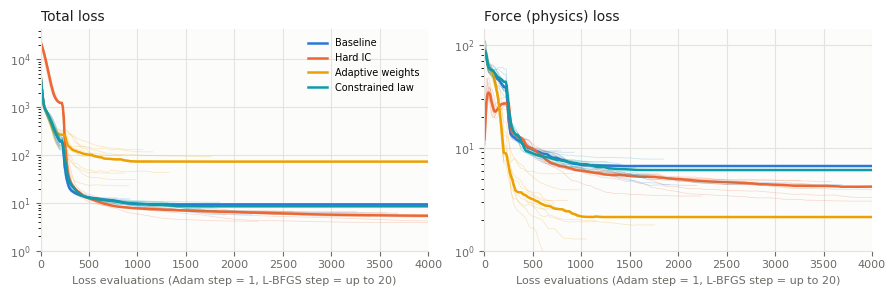

,median_loss_total,median_loss_force,median_position_mse
variant,,,
Baseline,8.820,6.415,1.330
Hard IC,5.339,4.159,0.590
Adaptive weights,73.070,2.124,35.525
Constrained law,8.483,6.072,1.261


In [9]:
INK, MUTED, GRID, SURFACE = "#1f1f1e", "#6b6a65", "#e4e3df", "#fcfcfb"   # text and background colours
COLORS = {'full': "#2a78d6", 'hic': "#eb6834", 'aw2': "#eda100", 'pull_tail_v0': "#0f9aa8"}   # one per variant
plt.rcParams.update({'font.size': 8, 'savefig.facecolor': 'white', 'savefig.dpi': 200})


def quiet_axis(axis, title, log_scale=True):
    """Light grid, no top/right frame, neutral text colours (and a log y-axis unless log_scale=False)."""
    axis.set_title(title, loc="left", color=INK, fontsize=10)
    if log_scale:
        axis.set_yscale("log")
    axis.grid(True, color=GRID, linewidth=0.8)
    axis.set_facecolor(SURFACE)
    for side in ("top", "right"):
        axis.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        axis.spines[side].set_color(GRID)
    axis.tick_params(colors=MUTED, labelsize=8)

LOG_SOURCE = RESULTS_DIR
PLOT_VARIANTS = ['full', 'hic', 'aw2', 'pull_tail_v0']
EVAL_GRID = np.arange(0, 4001, 10)     # common x-axis (loss evaluations) for the median curves


def median_curve(run_logs, column):
    """Median over runs of one loss column on EVAL_GRID; a finished run keeps its last value."""
    curves = []
    for log in run_logs:
        values = log[column].ffill().to_numpy()      # ffill: carry the last valid value over NaNs
        # np.interp: value at each grid point; beyond the last evaluation it repeats the final value
        curves.append(np.interp(EVAL_GRID, log.evals.to_numpy(), values))
    return np.median(curves, axis=0)


def plot_loss_curves(all_logs, path):
    """Total and physics loss against loss evaluations: each seed faint, the median bold."""
    figure, axes = plt.subplots(1, 2, figsize=(9, 3))
    for axis, (column, title) in zip(axes, [('loss_total', 'Total loss'), ('loss_force', 'Force (physics) loss')]):
        quiet_axis(axis, title)
        for variant in PLOT_VARIANTS:
            run_logs = [group for _, group in all_logs[all_logs.variant == variant].groupby('seed')]
            for log in run_logs:
                axis.plot(log.evals, log[column], color=COLORS[variant], linewidth=0.5, alpha=0.25)
            axis.plot(EVAL_GRID, median_curve(run_logs, column), color=COLORS[variant], linewidth=1.8,
                      label=VARIANTS[variant]['label'])
        axis.set_xlim(0, EVAL_GRID[-1])
        axis.set_ylim(1, None)
        axis.set_xlabel("Loss evaluations (Adam step = 1, L-BFGS step = up to 20)", color=MUTED)
    axes[0].legend(frameon=False, fontsize=7)
    figure.tight_layout()
    figure.savefig(path)
    plt.show()


all_logs = pd.read_csv(LOG_SOURCE / "training_logs.csv", float_precision="round_trip")
# Cumulative number of loss evaluations within each run (groupby + cumsum = running total per run)
all_logs['evals'] = all_logs.groupby(['variant', 'seed']).func_evals.cumsum()
FIGURES_DIR.mkdir(exist_ok=True)
plot_loss_curves(all_logs, FIGURES_DIR / "loss_curves.png")

coefficients = pd.read_csv(LOG_SOURCE / "learned_coefficients.csv", float_precision="round_trip")
coefficients['position_mse'] = (coefficients.loss_pos_x + coefficients.loss_pos_y) / 2
# Per variant: median final losses over the 10 seeds
summary = coefficients.groupby('variant', sort=False).agg(
    median_loss_total=('loss_total', 'median'),
    median_loss_force=('loss_force', 'median'), median_position_mse=('position_mse', 'median'))
summary.rename(index={key: VARIANTS[key]['label'] for key in VARIANTS}).round(3)